# 05. Свёрточные нейронные сети. Часть 2

## 0. Подготовка

In [31]:
import copy
import os
import random
import time
from pathlib import Path

import albumentations as A
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import accuracy_score, confusion_matrix
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms as T

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = Path("./data")
ARTIFACT_ROOT = Path("./seminar05_artifacts")
ARTIFACT_ROOT.mkdir(exist_ok=True)
TRACKING_URI = (Path.cwd() / "mlruns_seminar05").resolve().as_uri()
EXPERIMENT_NAME = "seminar05-cnn"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print({"torch": torch.__version__, "torchvision": torchvision.__version__, "device": str(device)})


{'torch': '2.4.0', 'torchvision': '0.19.0', 'device': 'cuda'}


### Локальный MLflow UI

После запуска хотя бы одного тренировочного блока запустим MLFlow:

```bash
mlflow ui --backend-store-uri ./mlruns_seminar05 --host 127.0.0.1 --port 5000
```

Если запускаете на remote, создайте SSH-туннель `ssh -L 5000:127.0.0.1:5000 <server>` и откройте `http://localhost:5000`.


## 1. Данные и базовые преобразования


In [40]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

raw_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=None)
raw_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=None)

rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(raw_train))
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 1200, 300, 500
train_indices = permutation[:TRAIN_SIZE]
val_indices = permutation[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE]
test_indices = np.arange(TEST_SIZE)

class CIFARSubset(Dataset):
    def __init__(self, base, indices, transform=None):
        self.base = base
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.base[int(self.indices[index])]
        if self.transform is not None:
            image = self.transform(image)
        return image, label


def normalize_transform():
    return T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])


def make_loaders(train_transform, batch_size=64, num_workers=0):
    eval_transform = normalize_transform()
    train_ds = CIFARSubset(raw_train, train_indices, train_transform)
    val_ds = CIFARSubset(raw_train, val_indices, eval_transform)
    test_ds = CIFARSubset(raw_test, test_indices, eval_transform)
    common = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    return (
        DataLoader(train_ds, shuffle=True, **common),
        DataLoader(val_ds, shuffle=False, **common),
        DataLoader(test_ds, shuffle=False, **common),
    )

basic_train_loader, val_loader, test_loader = make_loaders(normalize_transform())
print(len(basic_train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))


Files already downloaded and verified
Files already downloaded and verified
1200 300 500


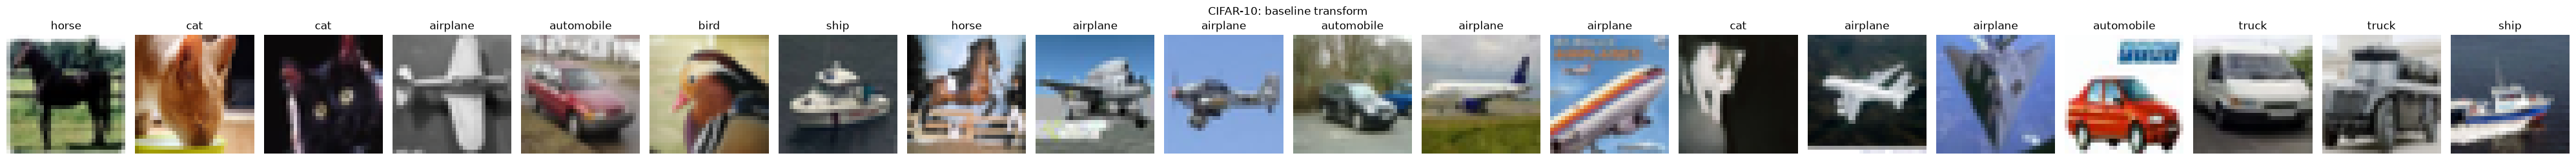

In [34]:
CLASS_NAMES = raw_train.classes


def show_images(images, labels, title, n=20):
    images = images[:n].detach().cpu().permute(0, 2, 3, 1).numpy()
    mean = np.asarray(CIFAR_MEAN)
    std = np.asarray(CIFAR_STD)
    images = np.clip(images * std + mean, 0, 1)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.5))
    for ax, image, label in zip(np.atleast_1d(axes), images, labels[:n]):
        ax.imshow(image)
        ax.set_title(CLASS_NAMES[int(label)])
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

images, labels = next(iter(basic_train_loader))
show_images(images, labels, "CIFAR-10: baseline transform")


## 2. CNN и цикл обучения в чистом PyTorch

In [35]:
class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, pool=True, dropout=0.0, activation=nn.ReLU):
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
                  nn.BatchNorm2d(out_channels), activation()]
        if pool:
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
        if dropout:
            layers.append(nn.Dropout2d(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class SmallCNN(nn.Module):
    def __init__(self, n_classes=10, activation=nn.ReLU):
        super().__init__()
        self.features = nn.Sequential(
            CNNBlock(3, 32, dropout=0.05, activation=activation),
            CNNBlock(32, 64, dropout=0.10, activation=activation),
            CNNBlock(64, 128, dropout=0.15, activation=activation),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

model = SmallCNN()
print(model(torch.randn(4, 3, 32, 32)).shape)


torch.Size([4, 10])


In [54]:
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss_sum += criterion(logits, y).item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            count += y.size(0)
    return loss_sum / count, correct / count


def train_torch(model, train_loader, val_loader, epochs=2, lr=3e-4, weight_decay=1e-4,
                run_name="torch-run", scheduler=None, scheduler_per_batch=False, patience=10,
                optimizer=None):
    """Explicit PyTorch loop: one training step, one validation pass, logging, checkpoint."""
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    best_loss, best_state, bad_epochs = float("inf"), None, 0
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"epochs": epochs, "lr": lr, "weight_decay": weight_decay, "device": str(device)})
        for epoch in range(epochs):
            model.train()
            train_loss, correct, count = 0.0, 0, 0
            for x, y in train_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                logits = model(x)
                loss = criterion(logits, y)
                loss.backward()
                optimizer.step()
                if scheduler is not None and scheduler_per_batch:
                    scheduler.step()
                train_loss += loss.item() * y.size(0)
                correct += (logits.argmax(1) == y).sum().item()
                count += y.size(0)
            val_loss, val_acc = evaluate(model, val_loader, criterion)
            train_loss, train_acc = train_loss / count, correct / count
            if scheduler is not None and not scheduler_per_batch:
                if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                    scheduler.step(val_loss)
                else:
                    scheduler.step()
            lr_now = optimizer.param_groups[0]["lr"]
            row = {"train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss,
                   "val_acc": val_acc, "lr": lr_now}
            history.append(row)
            mlflow.log_metrics(row, step=epoch)
            if val_loss < best_loss:
                best_loss, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    break
            print(f"epoch {epoch + 1}: train_acc={train_acc:.3f}, val_acc={val_acc:.3f}, lr={lr_now:.2e}")
        if best_state is not None:
            model.load_state_dict(best_state)
            checkpoint = ARTIFACT_ROOT / f"{run_name}.pt"
            torch.save(model.state_dict(), checkpoint)
            mlflow.log_artifact(str(checkpoint))
    return model, history


### 2.1. Базовый эксперимент

MLflow хранит параметры, метрики по эпохам и лучший checkpoint в локальной папке `mlruns_seminar05`.


**Пауза перед базовым запуском.**

Почему `CrossEntropyLoss` получает logits, а не вероятности? Что изменится, если забыть `model.eval()` на validation?


In [56]:
baseline_model, baseline_history = train_torch(
    SmallCNN(), basic_train_loader, val_loader, epochs=1000, run_name="baseline-pytorch"
)
val_loss, val_acc = evaluate(baseline_model, val_loader, nn.CrossEntropyLoss())
test_loss, test_acc = evaluate(baseline_model, test_loader, nn.CrossEntropyLoss())
print({"val_accuracy": val_acc, "test_accuracy": test_acc})


epoch 1: train_acc=0.158, val_acc=0.203, lr=3.00e-04
epoch 2: train_acc=0.278, val_acc=0.323, lr=3.00e-04
epoch 3: train_acc=0.302, val_acc=0.343, lr=3.00e-04
epoch 4: train_acc=0.331, val_acc=0.377, lr=3.00e-04
epoch 5: train_acc=0.362, val_acc=0.317, lr=3.00e-04
epoch 6: train_acc=0.364, val_acc=0.340, lr=3.00e-04
epoch 7: train_acc=0.390, val_acc=0.357, lr=3.00e-04
epoch 8: train_acc=0.383, val_acc=0.350, lr=3.00e-04
epoch 9: train_acc=0.378, val_acc=0.337, lr=3.00e-04
epoch 10: train_acc=0.372, val_acc=0.357, lr=3.00e-04
epoch 11: train_acc=0.403, val_acc=0.353, lr=3.00e-04
epoch 12: train_acc=0.401, val_acc=0.373, lr=3.00e-04
epoch 13: train_acc=0.417, val_acc=0.377, lr=3.00e-04
epoch 14: train_acc=0.422, val_acc=0.367, lr=3.00e-04
epoch 15: train_acc=0.417, val_acc=0.370, lr=3.00e-04
epoch 16: train_acc=0.412, val_acc=0.373, lr=3.00e-04
epoch 17: train_acc=0.451, val_acc=0.380, lr=3.00e-04
epoch 18: train_acc=0.433, val_acc=0.380, lr=3.00e-04
epoch 19: train_acc=0.443, val_acc=0.

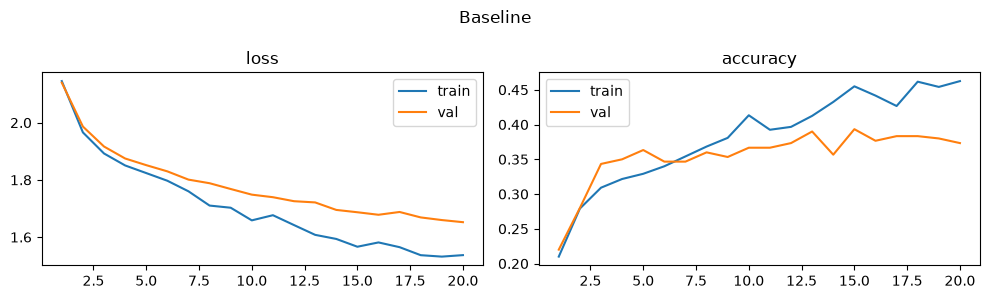

In [10]:
def plot_history(history, title):
    epochs = np.arange(1, len(history) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(epochs, [x["train_loss"] for x in history], label="train")
    axes[0].plot(epochs, [x["val_loss"] for x in history], label="val")
    axes[0].set_title("loss"); axes[0].legend()
    axes[1].plot(epochs, [x["train_acc"] for x in history], label="train")
    axes[1].plot(epochs, [x["val_acc"] for x in history], label="val")
    axes[1].set_title("accuracy"); axes[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(baseline_history, "Baseline")


### Что добавляет PyTorch Lightning

Lightning — это оболочка над PyTorch, которая отделяет исследовательский код от служебного цикла.

- `LightningModule`: `forward`, `training_step`, `validation_step`, `configure_optimizers`.
- `LightningDataModule`: откуда брать train/validation/test loaders.
- `Trainer`: эпохи, device, backpropagation, callbacks и checkpoint.
- `MLFlowLogger`: передаёт параметры и метрики в тот же локальный MLflow.

**Пауза.** В чистом PyTorch найдите в предыдущем коде четыре операции, которые теперь выполняет `Trainer`: переключение режима, `zero_grad`, `backward` и `optimizer.step`.


### 2.2. Тот же пример на PyTorch Lightning

Lightning берёт на себя цикл эпох, `zero_grad`, валидацию и вызов логгера. Архитектура модели остаётся обычным `nn.Module`.


`LightningModule` хранит сеть и описывает шаги; `Trainer.fit` запускает обучение и validation. MLflow подключается через `MLFlowLogger`.


In [58]:
import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import MLFlowLogger

class LoaderDataModule(L.LightningDataModule):
    def __init__(self, train_loader, val_loader, test_loader=None):
        super().__init__()
        self._train_loader, self._val_loader, self._test_loader = train_loader, val_loader, test_loader

    def train_dataloader(self): return self._train_loader
    def val_dataloader(self): return self._val_loader
    def test_dataloader(self): return self._test_loader


class LitClassifier(L.LightningModule):
    def __init__(self, network, lr=3e-4, weight_decay=1e-4):
        super().__init__()
        self.network = network
        self.lr, self.weight_decay = lr, weight_decay
        self.criterion = nn.CrossEntropyLoss()

    def forward(self, x): return self.network(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        acc = (logits.argmax(1) == y).float().mean()
        self.log(f"{stage}_loss", loss, prog_bar=True, on_epoch=True)
        self.log(f"{stage}_acc", acc, prog_bar=True, on_epoch=True)
        return loss

    def training_step(self, batch, batch_idx): return self._shared_step(batch, "train")
    def validation_step(self, batch, batch_idx): self._shared_step(batch, "val")
    def test_step(self, batch, batch_idx): self._shared_step(batch, "test")

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.lr, weight_decay=self.weight_decay)


def fit_lightning(module, loaders, run_name, max_epochs=1, callbacks=None):
    logger = MLFlowLogger(experiment_name=EXPERIMENT_NAME, tracking_uri=TRACKING_URI, run_name=run_name)
    trainer = L.Trainer(
        max_epochs=max_epochs, accelerator="auto", devices=1, logger=logger,
        callbacks=callbacks or [], enable_progress_bar=False, enable_model_summary=False,
        log_every_n_steps=1,
    )
    trainer.fit(module, datamodule=LoaderDataModule(*loaders[:2]))
    return trainer

lightning_baseline = fit_lightning(
    LitClassifier(SmallCNN()), (basic_train_loader, val_loader), "baseline-lightning", max_epochs=1
)


[transformers] Disabling PyTorch because PyTorch >= 2.5 is required but found 2.4.0
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
You are using a CUDA device ('NVIDIA GeForce RTX 4090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.or

In [59]:
L.Trainer?

Init signature:
L.Trainer(
    *,
    accelerator: Union[str, lightning.pytorch.accelerators.accelerator.Accelerator] = 'auto',
    strategy: Union[str, lightning.pytorch.strategies.strategy.Strategy] = 'auto',
    devices: Union[list[int], str, int] = 'auto',
    num_nodes: int = 1,
    precision: Union[Literal[64, 32, 16], Literal['transformer-engine', 'transformer-engine-float16', '16-true', '16-mixed', 'bf16-true', 'bf16-mixed', '32-true', '64-true'], Literal['64', '32', '16', 'bf16'], NoneType] = None,
    logger: Union[lightning.pytorch.loggers.logger.Logger, collections.abc.Iterable[lightning.pytorch.loggers.logger.Logger], bool, NoneType] = None,
    callbacks: Union[list[lightning.pytorch.callbacks.callback.Callback], lightning.pytorch.callbacks.callback.Callback, NoneType] = None,
    fast_dev_run: Union[int, bool] = False,
    max_epochs: Optional[int] = None,
    min_epochs: Optional[int] = None,
    max_steps: int = -1,
    min_steps: Optional[int] = None,
    max_time: Un

## 3. Аугментации

<img src="https://media.springernature.com/full/springer-static/image/art%3A10.1186%2Fs40537-019-0197-0/MediaObjects/40537_2019_197_Fig3_HTML.jpg?as=webp">

<img src="https://media.springernature.com/lw685/springer-static/image/art%3A10.1186%2Fs40537-019-0197-0/MediaObjects/40537_2019_197_Fig4_HTML.jpg?as=webp">

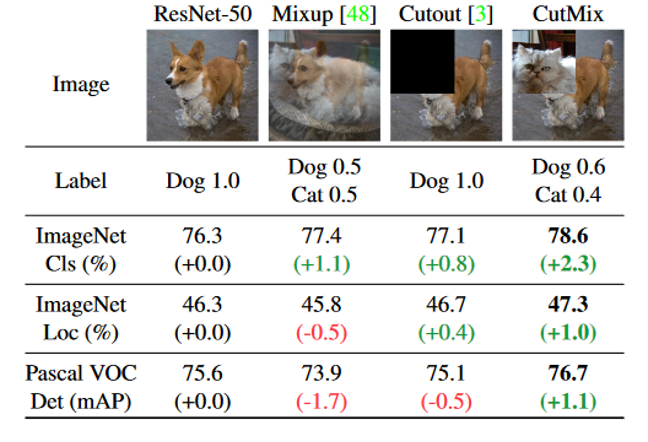

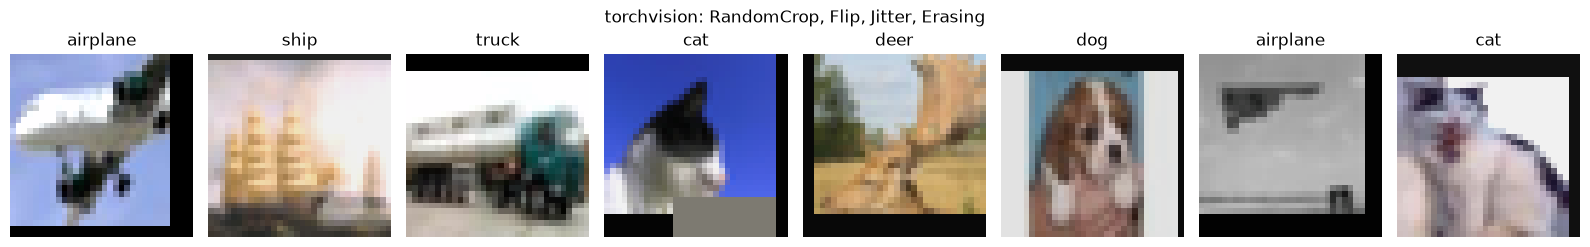

In [12]:
classic_transform = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
    T.RandomErasing(p=0.2, scale=(0.02, 0.15)),
])
classic_train_loader, _, _ = make_loaders(classic_transform)
classic_images, classic_labels = next(iter(classic_train_loader))
show_images(classic_images, classic_labels, "torchvision: RandomCrop, Flip, Jitter, Erasing")


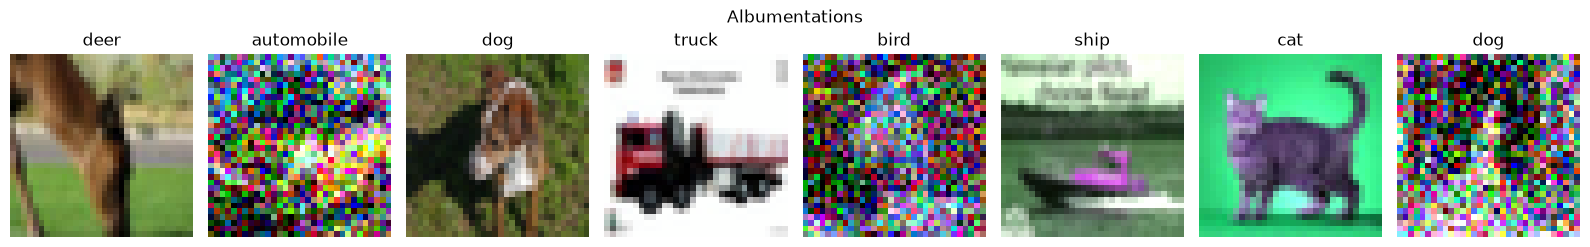

In [13]:
class AlbumentationsTransform:
    def __init__(self, transform): self.transform = transform
    def __call__(self, image):
        return self.transform(image=np.asarray(image))["image"]

albumentations_train = A.Compose([
    A.RandomCrop(32, 32, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.OneOf([A.GaussNoise(p=1.0), A.ColorJitter(p=1.0), A.Blur(blur_limit=3, p=1.0)], p=0.4),
    A.Normalize(mean=CIFAR_MEAN, std=CIFAR_STD),
    ToTensorV2(),
])
albumentations_eval = A.Compose([A.Normalize(mean=CIFAR_MEAN, std=CIFAR_STD), ToTensorV2()])
alb_train_loader, alb_val_loader, alb_test_loader = make_loaders(
    AlbumentationsTransform(albumentations_train)
)
# make_loaders uses the standard validation transform; show an Albumentations validation pipeline separately.
alb_demo_ds = CIFARSubset(raw_train, train_indices[:8], AlbumentationsTransform(albumentations_train))
alb_images, alb_labels = next(iter(DataLoader(alb_demo_ds, batch_size=8)))
show_images(alb_images, alb_labels, "Albumentations")


### 3.1. Обучение с Albumentations

**Пауза.** Какие преобразования должны применяться к validation? Только детерминированные `Normalize` и `ToTensorV2`: иначе метрика зависит от случайности аугментации.


In [ ]:
aug_model, aug_history = train_torch(
    SmallCNN(), alb_train_loader, alb_val_loader, epochs=2,
    run_name="albumentations-pytorch"
)
plot_history(aug_history, "Albumentations")


### 3.2. Albumentations на PyTorch Lightning

Здесь Lightning не меняет аугментации. `DataLoader` уже выдаёт готовые batch, а `LightningModule` описывает шаг обучения и метрики. `Trainer.fit` запускает цикл.


In [ ]:
lightning_aug = fit_lightning(
    LitClassifier(SmallCNN()), (alb_train_loader, alb_val_loader),
    "albumentations-lightning", max_epochs=1
)


## 4. Нормализация и стабильность обучения

Рассмотрим в качестве активации нечетную функцию с единичной производной в нуле.

Например, нам подойдет гиперболический тангенс (tanh)

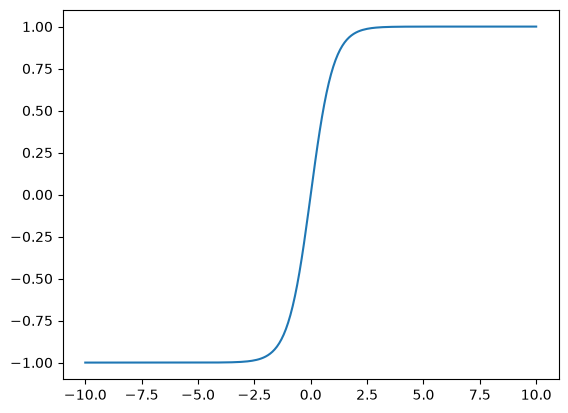

In [27]:
x = np.arange(-10, 10.1, 0.1)
plt.plot(x, np.tanh(x))
plt.show()

Мы хотим начать из линейного региона этой функции, чтобы избежать затухающих градиентов.

Как у нас зависят активации на текущем слое от активаций на предыдущем?

$$z^{i+1} = f(z^iW^i)$$

Тогда, так как мы вначале хотим находиться в районе линейности нашей функции, то

$$z^{i+1} \approx z^i W^i$$

Ответить на вопрос, а как будут связаны дисперсии этих активаций, сложнее

Сначала распишем:
1. чему равна дисперсия суммы двух независимых величин

$$D(\eta + \gamma) = D\eta + D\gamma$$

2. чему равна дисперсия произведений двух независимых величин


$$D\eta\gamma = E(\eta\gamma)^2 - (E\eta\gamma)^2 = E\eta^2E\gamma^2 - (E\eta)^2(E\gamma)^2$$

Далее распишем для одного веса текущего слоя

$$z^{i+1}_{k} = \sum_t z^i_t w_{kt}$$

$$D(z^{i+1}_{k}) = D(\sum_t z^i_t w_{kt}) = \sum_t D(z^i_t w_{kt})$$

Предполагая, что дисперсии весов и активаций одинаковые (а нам бы так хотелось)

$$D(z^{i+1}_{k}) = n D(z^i_0 w_{k0})$$

Далее применяем нашу формулу и получаем:

$$D(z^{i+1}_{k}) = n [E(z^i_0)^2E(w_{k0})^2 - (Ez^i_0)^2(Ew_{k0})^2]$$

Хотим, чтобы матожидание наших активаций оставалось равным нулю, и мы можем этого добиться, делая  матожидание весов равным 0.

$$D(z^{i+1}_{k}) =   n E(z^i_0)^2E(w_{k0})^2 $$

Заметим, что, так как матожидание активаций и весов равны 0, то матожидания их квадратов равны дисперсии активаций и весов соответственно:

$$D(z^{i}_{0}) = E(z^{i}_{0})^2 - (Ez^{i}_{0})^2 = E(z^{i}_{0})^2$$
$$D(w_{k0}) = E(w_{k0})^2 - (Ew_{k0})^2 = E(w_{k0})^2$$

Подставив их в выражение для $D(z^{i+1}_{k})$ получим:

$$D(z^{i+1}_{k}) = n D(z^i_0)D(w_{k0})$$


Отсюда можно вывести формулу для зависимости активаций любого слоя от весов предуыдущих слоев и дисперсии исходных данных

$$Dz^i = Dx \prod_{p=0}^{i-1}n_pDW^p $$

Где $n_p$ - размерность выхода слоя p-го слоя

Аналогично можно вывести формулу для градиентов по активациям


$$D(\dfrac {\delta L} {\delta z^i}) = D(\dfrac {\delta L} {\delta z^d} ) \prod_{p=i}^{d}n_{p+1}DW^p $$



Для хорошей инициализации нам бы хотелось, чтобы дисперсии активаций на всех слоях были одинаковые.
А еще хотелось бы, чтобы дисперсии градиентов тоже были одинаковые.

Тогда у нас не происходит резких скачков в распределении активаций, а градиент не затухает и не взрывается


$$Dz^i = Dz^j$$
$$D\dfrac {\delta L} {\delta z^i} = D\dfrac {\delta L} {\delta z^j}$$


Учитывая предыдущее, это эквивалентно тому, что мы требуем

$$n_iDW^i = 1$$
$$n_{i+1}DW^i = 1$$

Одновременно так сделать не получится $$n_i \ne n_{i+1}$$

Потому делаем компромисс - среднее гармонческое решений первого и второго уравнения

$$DW^i = \dfrac 2 {n_i + n_{i+1}}$$

Надо выбрать распределение.

$$ EW^i = 0 $$

$$DW^i = \dfrac 2 {n_i + n_{i+1}}$$

Можно было бы взять нормальное распределение с такими параметрами.

$$W_i \sim N(0, sd=\sqrt{\dfrac 2 {n_i + n_{i+1}}}) $$

А можно равномерное:

$$D(U[a, b]) = \dfrac 1 {12} (b -a)^2$$

Итого получим:
$$W_i \sim U[-\dfrac {\sqrt{6}} {n_i + n_{i + 1}}, \dfrac {\sqrt{6}} {n_i + n_{i + 1}} ]$$

In [26]:
# Input normalization and the train/eval behavior of BatchNorm.
raw_pixel = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
normalized_pixel = (raw_pixel - torch.tensor(CIFAR_MEAN).view(3, 1, 1)) / torch.tensor(CIFAR_STD).view(3, 1, 1)
bn_demo = nn.BatchNorm2d(3)
train_output = bn_demo(torch.randn(4, 3, 8, 8))
bn_demo.eval()
eval_output = bn_demo(torch.randn(4, 3, 8, 8))
print("normalized pixel:", normalized_pixel.flatten().tolist())
print("running mean:", bn_demo.running_mean.tolist())
print("train/eval shapes:", train_output.shape, eval_output.shape)

init_demo = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.Linear(16, 10))
nn.init.kaiming_normal_(init_demo[0].weight, nonlinearity="relu")
nn.init.xavier_uniform_(init_demo[2].weight)
print("Kaiming std:", init_demo[0].weight.std().item(), "Xavier std:", init_demo[2].weight.std().item())


normalized pixel: [0.03481779992580414, 0.07310063391923904, 0.20451070368289948]
running mean: [0.008946588262915611, 0.007474594749510288, -0.009148827753961086]
train/eval shapes: torch.Size([4, 3, 8, 8]) torch.Size([4, 3, 8, 8])
Kaiming std: 0.2694879174232483 Xavier std: 0.2790927290916443


## 5. Transfer learning

Как обучить нейросеть  на своих данных, когда их мало?

Можно взять обученную модель, заменить у нее несколько последних слоев и обучить только их.

Ранее обученные слои будут извлекать признаки (feature extractor), и полученные таким образом представления (embedding) будут классифицироваться вновь добавленными слоями.

<img src="https://data.bioml.ru/htdocs/courses/bioml/neural_networks/cnn/img/Transfer-learning.png">

**Неэффективность предобученных фильтров**
Не все фильтры предобученной модели могут быть полезными для новой задачи. Например, если мы работаем с изображениями еды, часть фильтров в скрытых слоях модели, обученной на ImageNet, окажется избыточной — ведь они могли быть настроены на распознавание объектов, не связанных с нашей предметной областью.

**Дообучение (fine-tuning)**
Чтобы адаптировать модель под конкретную задачу, после обучения нового классификатора можно дообучить часть или все промежуточные слои. При этом важно использовать меньший learning rate, чем при обучении с нуля: предобученные веса уже хорошо справляются с частью задач, и слишком агрессивное обновление может ухудшить их работу.

Такой подход называется fine-tuning (тонкая настройка) — мы не просто добавляем новые слои, но и аккуратно подстраиваем уже существующие под нашу задачу.

Иногда fine-tuning отождествляют с transfer learning (переносом обучения). В таком контексте:

Backbone — предобученная часть сети, извлекающая признаки.

Head — новые слои, отвечающие за конкретную задачу.

Ключевой этап — подбор модели, обученной на данных, схожих с нашей задачей. Основная идея transfer learning заключается в том, что признаки, извлеченные такой моделью, будут полезны и для нового домена. Чем ближе исходная и целевая области (например, схожие типы изображений), тем эффективнее перенос знаний.

**Пример**:
Для большинства задач компьютерного зрения стандартным выбором являются модели, обученные на ImageNet.

In [21]:
from torchvision import models

model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

**Принцип заморозки предобученных слоев**

Основная идея заключается в том, что начальные слои нейронной сети уже содержат полезные признаки (например, простые текстуры и границы для изображений), которые не требуют существенного изменения. При добавлении новых случайно инициализированных слоев возникает риск:

- На первых итерациях обучения новые слои генерируют значительную ошибку
- Большие градиенты могут радикально изменить тщательно настроенные веса предобученных слоев
- Это приведет к потере уже имеющихся полезных признаков

На практике заморозка означает **отключение подсчета градиентов.**

In [22]:
# Freeze model parameters
for param in model.parameters():
    param.requires_grad = False

В отличие от начальных слоев, которые извлекают универсальные признаки (например, границы или текстуры), финальные слои нейросети обладают важными особенностями

Поэтому при transfer learning необходимо:
- Заменить финальные слои на новые, соответствующие целевой задаче
- Инициализировать их веса случайным образом (так как старые веса теряют актуальность)
- Сфокусировать начальное обучение именно на этих новых слоях

In [23]:
from torch import nn

model.classifier[6] = nn.Linear(4096, len(CLASS_NAMES), bias=True)

### Запуск модифицированного AlexNet

После заморозки backbone обучаем только новый `classifier[6]`. Для AlexNet нужны его стандартные resize/crop и normalization transforms.


In [25]:
def alexnet_normalize_transform():
    return T.Compose([T.Resize(224), T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])


def alexnet_make_loaders(train_transform, batch_size=64, num_workers=0):
    eval_transform = alexnet_normalize_transform()
    train_ds = CIFARSubset(raw_train, train_indices, train_transform)
    val_ds = CIFARSubset(raw_train, val_indices, eval_transform)
    test_ds = CIFARSubset(raw_test, test_indices, eval_transform)
    common = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    return (
        DataLoader(train_ds, shuffle=True, **common),
        DataLoader(val_ds, shuffle=False, **common),
        DataLoader(test_ds, shuffle=False, **common),
    )

### Обучение изменённого AlexNet в чистом PyTorch

Backbone заморожен, поэтому optimizer обновляет новый классификатор. Для сравнения с базовой CNN считаем те же validation/test accuracy. На этом teaching subset запускается одна эпоха; для качества число эпох нужно увеличить.


In [ ]:
alexnet_weights = models.AlexNet_Weights.DEFAULT
alexnet_preprocess = alexnet_weights.transforms()
alexnet_train_loader, alexnet_val_loader, alexnet_test_loader = alexnet_make_loaders(
    alexnet_preprocess, batch_size=32
)

alexnet_model = model.to(device)
alexnet_model, alexnet_history = train_torch(
    alexnet_model,
    alexnet_train_loader,
    alexnet_val_loader,
    epochs=100,
    lr=1e-4,
    run_name="alexnet-linear-probe",
)
alexnet_val_loss, alexnet_val_acc = evaluate(
    alexnet_model, alexnet_val_loader, nn.CrossEntropyLoss()
)
alexnet_test_loss, alexnet_test_acc = evaluate(
    alexnet_model, alexnet_test_loader, nn.CrossEntropyLoss()
)
print({
    "val_accuracy": alexnet_val_acc,
    "test_accuracy": alexnet_test_acc,
    "trainable_parameters": sum(p.numel() for p in alexnet_model.parameters() if p.requires_grad),
})

# must give an error! what's about Resize(224)?


### Модифицированный AlexNet в Lightning

Собираем модель. Замороженные параметры остаются частью модели, но optimizer обновляет только голову.

In [ ]:
alexnet_lightning_model = models.alexnet(weights=alexnet_weights)
for parameter in alexnet_lightning_model.parameters():
    parameter.requires_grad_(False)
alexnet_lightning_model.classifier[6] = nn.Linear(4096, len(CLASS_NAMES))

lightning_alexnet = fit_lightning(
    LitClassifier(alexnet_lightning_model, lr=1e-4),
    (alexnet_train_loader, alexnet_val_loader),
    "alexnet-linear-probe-lightning", max_epochs=1
)

### 6.1. Learning-rate range test

В зависимости от выбранного learning rate нейросеть может сходиться с разной скоростью и с разным качеством.

Как выбрать хороший learning rate?

1. Просто берем и либо делаем для каждого learning rate, который хотим проверить, минимизацию одну эпоху (чтобы всю выборку увидеть), нейросетку для каждого значения learning rate инициализируем заново

Это долго. Потому  делаем финт ушами:

2. На каждое значение learning rate у нас будет лишь один батч, нейросетку для каждого learning rate не меняем. И это часто работает, так как нам нужна просто грубая прикидка


<img src="https://data.bioml.ru/htdocs/courses/bioml/neural_networks/nn_training/img/optimizators/learing_rate_finder_lr_plot.png" width="640">

In [ ]:
from itertools import cycle


def lr_range_test(model, loader, start_lr=1e-6, end_lr=1.0, num_steps=24, run_name="lr-range-pytorch"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=start_lr)
    multiplier = (end_lr / start_lr) ** (1 / max(num_steps - 1, 1))
    lrs, losses = [], []
    smooth_loss, best_loss = None, float("inf")
    iterator = iter(loader)
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"start_lr": start_lr, "end_lr": end_lr, "num_steps": num_steps})
        model.train()
        for step in range(num_steps):
            try:
                x, y = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                x, y = next(iterator)
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            value = float(loss.detach().cpu())
            smooth_loss = value if smooth_loss is None else 0.98 * smooth_loss + 0.02 * value
            lr_now = optimizer.param_groups[0]["lr"]
            lrs.append(lr_now)
            losses.append(smooth_loss)
            mlflow.log_metric("lr_range_loss", smooth_loss, step=step)
            if not np.isfinite(smooth_loss) or (step > 2 and smooth_loss > 4 * best_loss):
                break
            best_loss = min(best_loss, smooth_loss)
            optimizer.param_groups[0]["lr"] = lr_now * multiplier
    return np.asarray(lrs), np.asarray(losses)

lr_model = SmallCNN()
lr_values, lr_losses = lr_range_test(lr_model, basic_train_loader)
plt.figure(figsize=(6, 3))
plt.plot(lr_values, lr_losses)
plt.xscale("log")
plt.xlabel("learning rate")
plt.ylabel("smoothed loss")
plt.title("LR range test")
plt.show()
print("candidate LR:", float(lr_values[np.argmin(lr_losses)]))


### LR range test на PyTorch Lightning

В Lightning тот же перебор запускается через `Tuner.lr_find`; найденное значение можно использовать для нового `Trainer.fit`.


In [ ]:
from lightning.pytorch.tuner import Tuner

lr_lightning_model = LitClassifier(SmallCNN(), lr=1e-3)
lr_logger = MLFlowLogger(experiment_name=EXPERIMENT_NAME, tracking_uri=TRACKING_URI, run_name="lr-range-lightning")
lr_trainer = L.Trainer(
    max_epochs=1, accelerator="auto", devices=1, logger=lr_logger,
    enable_progress_bar=False, enable_model_summary=False, log_every_n_steps=1,
)
lr_finder = Tuner(lr_trainer).lr_find(
    lr_lightning_model,
    datamodule=LoaderDataModule(basic_train_loader, val_loader),
    min_lr=1e-6, max_lr=1.0, num_training=12,
    mode="exponential", early_stop_threshold=None,
)
print("Lightning suggestion:", lr_finder.suggestion())


## 6. Планирование LR и early stopping

In [ ]:
scheduler_model = SmallCNN()
scheduler_optimizer = torch.optim.AdamW(scheduler_model.parameters(), lr=3e-4, weight_decay=1e-4)
plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(scheduler_optimizer, mode="min", patience=0, factor=0.5)
scheduler_model, scheduler_history = train_torch(
    scheduler_model, basic_train_loader, val_loader, epochs=2, lr=3e-4,
    run_name="reduce-on-plateau-pytorch", scheduler=plateau, patience=2, optimizer=scheduler_optimizer
)

step_model = SmallCNN()
step_scheduler = torch.optim.lr_scheduler.StepLR(
    torch.optim.AdamW(step_model.parameters(), lr=3e-4), step_size=1, gamma=0.5
)
step_model, step_history = train_torch(
    step_model, basic_train_loader, val_loader, epochs=1,
    run_name="step-lr-pytorch", scheduler=step_scheduler, optimizer=step_scheduler.optimizer
)

cosine_model = SmallCNN()
cosine_optimizer = torch.optim.AdamW(cosine_model.parameters(), lr=3e-4)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    cosine_optimizer, T_max=len(basic_train_loader)
)
cosine_model, cosine_history = train_torch(
    cosine_model, basic_train_loader, val_loader, epochs=1,
    run_name="cosine-lr-pytorch", scheduler=cosine_scheduler, scheduler_per_batch=True, optimizer=cosine_optimizer
)


### Планировщики и early stopping на PyTorch Lightning


In [ ]:
class LitScheduledClassifier(LitClassifier):
    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=2)
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}

lightning_scheduled = fit_lightning(
    LitScheduledClassifier(SmallCNN()), (basic_train_loader, val_loader),
    "cosine-lr-lightning", max_epochs=2,
    callbacks=[EarlyStopping(monitor="val_loss", patience=1, mode="min")]
)


## 7. Просмотр результатов MLflow

Открыть UI можно командой `mlflow ui --backend-store-uri ./mlruns_seminar05`.


In [ ]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], output_format="pandas")
columns = [c for c in ["run_id", "tags.mlflow.runName", "metrics.val_acc", "metrics.val_loss"] if c in runs]
print(runs[columns].sort_values("metrics.val_acc", ascending=False).head(10).to_string(index=False))
